# 05 Learning

978 areas have a rule type but no published hours. Predict them from nearby areas of the same
class, and decide where not to: a wrong "free" costs a driver a fine. The stage runs in
[`analysis/learning.py`](../../analysis/learning.py); the tables are the report's.

*Runs offline in a few seconds.*

In [1]:
import os
import sys
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline").is_dir()))
sys.path.insert(0, "analysis")

import geopandas as gpd
import pandas as pd
from IPython.display import Markdown

import learning
import report_stats as rs

pd.set_option("display.max_colwidth", None)
areas = gpd.read_parquet(rs.SOURCE)
results = learning.run(areas)

## 1. The task

Supervised classification: the label is an area's hours pattern, such as
`{"mon_fri": [9, 21], "sat": [9, 18]}`. We learn from official areas whose rule type needs hours,
and predict the `missing_hours` ones.

In [2]:
Markdown(rs.learning_classes(results))

### Areas to learn from and to predict, by class

|   Class |   Labelled |   To predict |   Patterns |   Most common % |
|--------:|-----------:|-------------:|-----------:|----------------:|
|       1 |         52 |          353 |          9 |            36.5 |
|       2 |         12 |           18 |          1 |           100   |
|       3 |         25 |            0 |          4 |            64   |
|       4 |         78 |            3 |          2 |            98.7 |
|       5 |        458 |           56 |          6 |            51.1 |
|       6 |       2585 |          437 |          5 |            50.3 |
|       7 |        400 |           29 |          5 |            70.5 |
|       8 |       1587 |           10 |          7 |            92.9 |
|       9 |        234 |           36 |         21 |            53.8 |
|      10 |        230 |           36 |          4 |            90.4 |


Class 1, free short-term parking, is the hard part: over a third of the areas to predict, few
labelled examples, many patterns.

## 2. Model and test

A distance-weighted vote of the *k* nearest labelled areas of the same class, the method
exploration chose ([04](04_exploration.ipynb), §8). It is tested where it will be used: for each
area to predict, a labelled area of the same class stands in, its neighbours hidden out to that
area's real distance, over twenty rounds; a second test holds out whole districts. An answer is
**unsafe** when the true rule applies at an hour the prediction misses: the app would say free
where the driver must pay or move.

In [3]:
Markdown(rs.learning_scores(results))

The 978 areas without hours sit a median of 174 m, centre to centre, from a labelled area of their class; each test hides neighbours out to those distances.

### Predicting the missing hours, at the distances they really face

| Method                                            |   Accuracy % |   Macro F1 |   Unsafe % |
|:--------------------------------------------------|-------------:|-----------:|-----------:|
| Always the most common pattern                    |         28.3 |      0.012 |       43   |
| Always the most common pattern of the class       |         48.1 |      0.047 |       26.6 |
| Nearest neighbours, k=1                           |         60.7 |      0.206 |       22.7 |
| Nearest neighbours, k=3                           |         61.7 |      0.204 |       23.3 |
| Nearest neighbours, k=5                           |         61.8 |      0.186 |       24.2 |
| Nearest neighbours, k=5, whole districts held out |         63.8 |      0.105 |       13.6 |


Used everywhere, it would cause fines.

## 3. When to show an estimate: the cut-off

The model always has a guess, but a guess is not always good enough to show. The **cut-off** decides,
area by area, whether the app shows the estimate or says *check the sign*. An estimate is shown only
if both hold:

1. the **nearest** known area of the same class is **within 150 m**, and
2. its **5 nearest** known areas **all have the same hours**.

Three real areas without hours, with their 5 nearest known neighbours:

In [4]:
neighbours = learning.Neighbours(results["labelled"])
targets, predicted, cut = results["targets"], results["predicted"], results["cut"]
shown = predicted[predicted["answer"]].sort_values("nearest")
examples = {
    "shown": shown.index[len(shown) // 2],
    "too far": predicted[(predicted["share"] == 1) & (predicted["nearest"] > 1.5 * cut["distance"])].sort_values("nearest").index[0],
    "neighbours disagree": predicted[(predicted["nearest"] <= cut["distance"]) & (predicted["share"] < 1)].sort_values("nearest").index[0],
}
rows = []
for outcome, i in examples.items():
    found = neighbours.nearest(targets.at[i, "luokka"], learning.xy(targets.loc[[i]])[0], cut["k"])
    rows.append({"area": targets.at[i, "id"], "district": targets.at[i, "district"], "outcome": outcome,
                 **{f"neighbour {n + 1}": f"{d:.0f} m: {rs.readable(h)}" for n, (d, h) in enumerate(found)}})
pd.DataFrame(rows).set_index("area")

,district,outcome,neighbour 1,neighbour 2,neighbour 3,neighbour 4,neighbour 5
area,,,,,,,
10378,VALLILA,shown,77 m: mon_fri 9-21,79 m: mon_fri 9-21,79 m: mon_fri 9-21,92 m: mon_fri 9-21,156 m: mon_fri 9-21
9027,VALLILA,too far,225 m: mon_fri 9-21,234 m: mon_fri 9-21,238 m: mon_fri 9-21,249 m: mon_fri 9-21,254 m: mon_fri 9-21
10860,REIJOLA,neighbours disagree,7 m: mon_fri 8-20,1414 m: mon_fri 8-17,1420 m: mon_fri 8-17,1425 m: mon_fri 8-17,1897 m: mon_fri 6-24


**Where 150 m and "all 5 agree" come from.** Before seeing any result we fixed the bar for an estimate
we are willing to show: at most **5% wrong**, and under **1% unsafe**, wrong in the way that costs a
fine. Then we started strict and loosened the distance step by step, measuring both on half of the
test rounds:

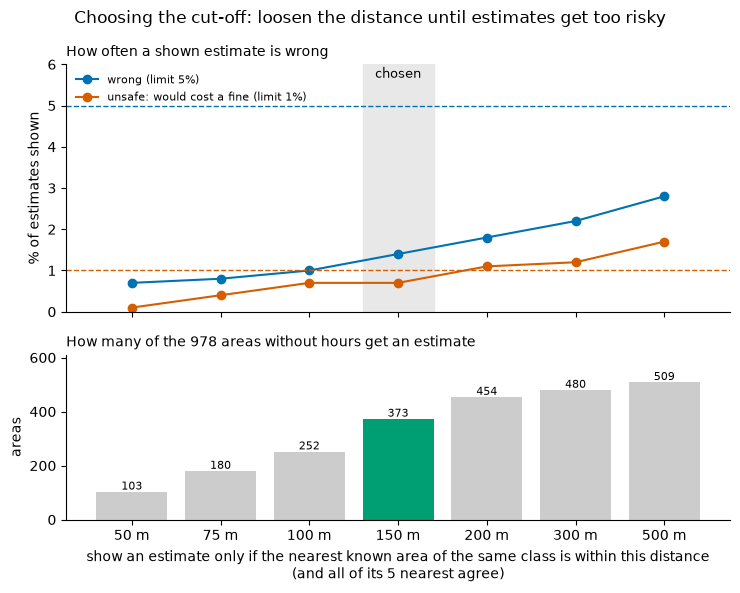

In [5]:
rs.plot_cutoff(results);

Read the top panel left to right: as the distance loosens, estimates get riskier. *Wrong* stays far
below its 5% line; *unsafe* is the one that crosses its 1% line, between 150 and 200 m. So 150 m is
the loosest distance still under both lines, and the bottom panel shows what that buys. Requiring all
five neighbours to agree is what makes 150 m possible; with a looser agreement, the bar holds only at
shorter distances.

Finally, the check: the same cut-off on the half of the rounds it was not chosen on, and with whole
districts held out.

In [6]:
Markdown(rs.learning_cutoff(results))

Cut-off: the 5 nearest same-class areas, the nearest within 150 m, all agreeing. Of the 978 areas without hours, **373** get an answer.

### The cut-off, on tests it was not chosen on

| Test                                     |   Answered % |   Accuracy % |   Unsafe % |
|:-----------------------------------------|-------------:|-------------:|-----------:|
| Simulation, rounds not used to choose it |         35.5 |         99.4 |        0.3 |
| Whole districts held out                 |          6.9 |         98.5 |        0   |


## 4. Who it answers

In [7]:
Markdown(rs.learning_by_class(results))

### The cut-off by parking class

|   Class |   To predict |   Answered |   Accuracy % without cut-off |   Accuracy % with |   Unsafe % with |   Simulated answers |
|--------:|-------------:|-----------:|-----------------------------:|------------------:|----------------:|--------------------:|
|       1 |          353 |          1 |                         11.4 |              81.8 |            18.2 |                  11 |
|       2 |           18 |          0 |                              |                   |                 |                   0 |
|       4 |            3 |          3 |                         96.7 |             100   |             0   |                  29 |
|       5 |           56 |         29 |                         85.7 |              98.5 |             1   |                 201 |
|       6 |          437 |        314 |                         96.2 |              99.5 |             0.2 |                2970 |
|       7 |           29 |         10 |                         82.8 |              98.5 |             1.5 |                  68 |
|       8 |           10 |         10 |                        100   |             100   |             0   |                  96 |
|       9 |           36 |          4 |                         45.6 |             100   |             0   |                  18 |
|      10 |           36 |          2 |                         83.6 |             100   |             0   |                  16 |


Class 1 almost never: its few neighbours rarely agree. Classes 5 and 7 sit at the edge of a bar set
for all classes together.

In [8]:
Markdown(rs.coverage_by_district(areas, results))

### Coverage per district, before and after prediction

| District      |   Areas |   Without hours |   Answered before |   Gained |   Before % |   After % |
|:--------------|--------:|----------------:|------------------:|---------:|-----------:|----------:|
| REIJOLA       |     597 |             330 |               258 |       53 |       43.2 |      52.1 |
| VALLILA       |     569 |             294 |               262 |      230 |       46   |      86.5 |
| ALPPIHARJU    |     305 |             117 |               180 |       46 |       59   |      74.1 |
| MUNKKINIEMI   |     592 |              75 |               508 |        6 |       85.8 |      86.8 |
| PASILA        |     146 |              61 |                74 |        5 |       50.7 |      54.1 |
| HAAGA         |     504 |              30 |               468 |        0 |       92.9 |      92.9 |
| TAKA-TÖÖLÖ    |     554 |              25 |               515 |        1 |       93   |      93.1 |
| ULLANLINNA    |    1330 |              19 |              1281 |       12 |       96.3 |      97.2 |
| LAUTTASAARI   |     790 |               8 |               778 |        5 |       98.5 |      99.1 |
| VIRONNIEMI    |     795 |               7 |               752 |        6 |       94.6 |      95.3 |
| KALLIO        |    1009 |               6 |               941 |        6 |       93.3 |      93.9 |
| KAMPINMALMI   |    1471 |               5 |              1330 |        3 |       90.4 |      90.6 |
| VANHAKAUPUNKI |      48 |               1 |                27 |        0 |       56.2 |      56.2 |


Reijola has the largest gap and gains little, because its gap is class 1.

## 5. Errors: what goes wrong

The test rounds held back for checking give guesses whose true hours we know. Two views: every guess,
as if there were no cut-off, and only the estimates the cut-off lets through. *Costs a fine* is
**yes** when the true rule applies at an hour the estimate says it does not.

In [9]:
Markdown(rs.learning_errors(results))

### Commonest mistakes, if every guess were shown

3,679 of 9,600 guesses wrong, 2,282 of them costing a fine.

| True hours             | Estimate               | Costs a fine   |   Times |
|:-----------------------|:-----------------------|:---------------|--------:|
| mon_fri 8-20           | mon_fri 8-17           | yes            |     418 |
| mon_fri 8-17           | mon_fri 8-20           | no             |     317 |
| mon_fri 8-17           | mon_fri 8-17, sat 9-15 | no             |     273 |
| mon_fri 8-17, sat 9-15 | mon_fri 8-17           | yes            |     245 |
| mon_fri 6-24           | mon_fri 8-17           | yes            |     196 |

### Commonest mistakes, among the estimates the cut-off shows

22 of 3,409 guesses wrong, 11 of them costing a fine.

| True hours                       | Estimate               | Costs a fine   |   Times |
|:---------------------------------|:-----------------------|:---------------|--------:|
| mon_fri 9-21, sat 9-18           | mon_fri 9-21           | yes            |       8 |
| mon_fri 9-21                     | mon_fri 9-21, sat 9-18 | no             |       7 |
| mon_fri 9-17                     | mon_fri 9-21           | no             |       3 |
| mon_fri 7-18                     | mon_fri 8-17           | yes            |       2 |
| mon_fri 9-21, sat 9-21, sun 9-21 | mon_fri 9-21, sat 9-18 | yes            |       1 |


Read the first row of each table as a sentence. Without the cut-off, the commonest mistake is
guessing weekdays 8-17 where the sign says 8-20: a driver arriving after 17:00 would think the rule
is over, though it applies until 20:00. With the cut-off, the commonest is guessing weekdays 9-21 where Saturday 9-18 is paid
too: a driver would think Saturday is free.

## 6. Reflection

**Hands on:** hours for 373 areas, about 99 in 100 right in the test, ready to show in the app as
labelled estimates, the change shipping next.

**The canvas planned** same-class nearest neighbours, a dummy baseline, district-blocked validation,
a test at the real distances, and a cut-off favouring accuracy.

**What worked:** testing at the real distances set an honest expectation, and the cut-off turned a
weak model into a strict one.

**What did not, and why:** class 1, the largest group, gets almost nothing; rare patterns are rarely
predicted; holding out districts leaves too few close neighbours to answer much.

**What changed:** no same-street feature, since the register has no street names; the test matched
class as well as distance; a class-level baseline; the unsafe rate, which became the binding limit.

**Imputation, for a driver:** about 3 in 1,000 estimates unsafe in the test. The gains go to the
paid districts near the centre; the suburbs and disc districts keep *check the sign*.

**What we would do differently:** define the unsafe measure first; it decided more than accuracy.

**Future steps:** labelled data for class 1, from traffic signs or drivers; a cut-off per class;
predicting whole streets rather than single areas.

**Experience and learning:** the validation design mattered more than the model. A simple model
with an honest test and the right to abstain beats a better one tested on easy cases.

> *Each of us: one line on what you took from this stage.*